## 0. Imports, seed, device

In [4]:
import os, re, glob, time, math, copy, random, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from tqdm.auto import tqdm
from skimage.registration import phase_cross_correlation
from skimage.metrics import structural_similarity

warnings.filterwarnings("ignore")

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
print("Using device:", device)

Using device: cuda


## 1. Settings (both datasets, levels 1-10, one training run)

In [5]:
# ---------------- SETTINGS (edit here only) ----------------
ROOT = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()

INIT_MODE   = "pretrained"   # "pretrained" = fine-tune official NAFNet-GoPro weights | "scratch" = random init
SCALE       = 4              # downscale factor (4 -> 365x590 images)
CROP        = 256            # training crop (multiple of 16)
BATCH       = 8              # lower to 4 if you get CUDA out-of-memory
TOTAL_ITERS = 10000          # training iterations (ONE run for all 10 levels)
VAL_EVERY   = 500
LR_FINETUNE = 2e-4
LR_SCRATCH  = 1e-3
USE_AMP     = True           # set False if the loss ever becomes NaN
ALIGN       = True           # align CAM01 (sharp) to CAM02 (blurred) with an integer shift
MAX_SHIFT   = 60             # px at full resolution; larger estimated shifts are ignored
HOLDOUT_PER_GROUP = 3        # validation samples per (level, font)  -> same held-out images as before
FIGURE_FONT = "timesR"       # "timesR" or "verdanaRef"

# Both zips are used together: steps 0..4 (= Levels 1..5) and steps 5..9 (= Levels 6..10)
DATASETS = ["steps_0_to_4", "steps_5_to_9"]
LEVELS   = {n: n - 1 for n in range(1, 11)}      # Level n -> focusStep_(n-1)

TAG      = "steps0to9"                           # used in every saved file name
RUN_NAME = f"{INIT_MODE}_{TAG}"
os.makedirs(f"{ROOT}/results", exist_ok=True)
print("ROOT:", ROOT, "| mode:", INIT_MODE, "| scale: 1/%d" % SCALE, "| levels:", list(LEVELS))

ROOT: /kaggle/working | mode: pretrained | scale: 1/4 | levels: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


## 2. Download + extract both datasets (in parallel)

In [6]:
import subprocess

def data_dir(name):
    return f"{ROOT}/data_{name}"

def present(name):
    return any("__MACOSX" not in h for h in glob.glob(f"{data_dir(name)}/**/CAM*2_blurred", recursive=True))

todo = [n for n in DATASETS if not present(n)]

for n in todo:   # sequential, so Zenodo isn't hit twice at once
    url = f"https://zenodo.org/records/5713637/files/{n}.zip?download=1"
    for attempt in range(5):
        print(f"downloading {n} (attempt {attempt+1}) ...")
        rc = subprocess.call(["wget", "-c", "--tries=3", "--timeout=60",
                              "--progress=dot:giga", url, "-O", f"{ROOT}/{n}.zip"])
        if rc == 0:
            break
        time.sleep(10)
    assert rc == 0, f"download of {n} failed (wget exit {rc}) - check Internet is ON in notebook settings"

for n in todo:
    os.makedirs(data_dir(n), exist_ok=True)
    get_ipython().system(f'unzip -q -n "{ROOT}/{n}.zip" -d "{data_dir(n)}"')
    os.remove(f"{ROOT}/{n}.zip")
for n in DATASETS:
    print(n, "ready:", present(n))

downloading steps_0_to_4 (attempt 1) ...


--2026-10-25 11:41:56--  https://zenodo.org/records/5713637/files/steps_0_to_4.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.42.113, 188.185.45.63, 188.185.40.132, ...
Connecting to zenodo.org (zenodo.org)|188.185.42.113|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3046101054 (2.8G) [application/octet-stream]
Saving to: ‘/kaggle/working/steps_0_to_4.zip’

     0K ........ ........ ........ ........  1%  619K 79m15s
 32768K ........ ........ ........ ........  2%  614K 78m40s
 65536K ........ ........ ........ ........  3% 1.05M 66m46s
 98304K ........ ........ ........ ........  4% 23.3M 50m0s
131072K ........ ........ ........ ........  5% 3.27M 42m20s
163840K ........ ........ ........ ........  6% 10.9M 35m34s
196608K ........ ........ ........ ........  7% 4.13M 31m40s
229376K ........ ........ ........ ........  8% 3.00M 29m13s
262144K ........ ........ ........ ........  9% 3.11M 27m13s
294912K ........ ........ ........ ........ 11% 3.3

downloading steps_5_to_9 (attempt 1) ...


Resolving zenodo.org (zenodo.org)... 188.185.51.60, 188.185.42.113, 188.185.47.192, ...
Connecting to zenodo.org (zenodo.org)|188.185.51.60|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2998257513 (2.8G) [application/octet-stream]
Saving to: ‘/kaggle/working/steps_5_to_9.zip’

     0K ........ ........ ........ ........  1%  764K 63m10s
 32768K ........ ........ ........ ........  2%  621K 69m37s
 65536K ........ ........ ........ ........  3% 1.95M 53m45s
 98304K ........ ........ ........ ........  4% 2.61M 44m13s
131072K ........ ........ ........ ........  5% 2.58M 38m27s
163840K ........ ........ ........ ........  6% 3.96M 33m32s
196608K ........ ........ ........ ........  7% 3.74M 30m5s
229376K ........ ........ ........ ........  8% 2.67M 28m2s
262144K ........ ........ ........ ........ 10% 8.49M 25m10s
294912K ........ ........ ........ ........ 11% 2.69M 23m56s
327680K ........ ........ ........ ........ 12% 2.73M 22m53s
360448K ........ ........

steps_0_to_4 ready: True
steps_5_to_9 ready: True


## 3. Build one combined list of image pairs (steps 0-9)

In [7]:
def find_dir(base, pattern):
    hits = [h for h in glob.glob(f"{base}/**/{pattern}", recursive=True)
            if "__MACOSX" not in h and os.path.isdir(h)]      # ignore macOS junk folder from the zip
    assert hits, f"{pattern} not found under {base}"
    return hits[0]

dfs = []
for n in DATASETS:
    bdir  = find_dir(data_dir(n), "CAM*2_blurred")
    sdir  = find_dir(data_dir(n), "CAM*1_focused")
    print(n, "| blur:", bdir, "| sharp:", sdir)
    blur_files  = {f for f in os.listdir(bdir) if not f.startswith("._")}
    sharp_files = {f for f in os.listdir(sdir) if not f.startswith("._")}
    rows = []
    for f in sorted(blur_files):
        if not f.lower().endswith((".tif", ".tiff")) or f not in sharp_files:
            continue
        stem = os.path.splitext(f)[0]
        if (stem + ".txt") not in blur_files:              # skip natural images / QR / calibration targets
            continue
        ms = re.search(r"focusStep_(\d+)", f)
        step = int(ms.group(1)) if ms else 0
        low = f.lower()
        font = "timesR" if "times" in low else ("verdanaRef" if "verdana" in low else "other")
        nums = re.findall(r"(\d+)", stem)
        rows.append(dict(name=f, step=step, font=font, sample=int(nums[-1]) if nums else 0))
    if not rows:
        raise RuntimeError(f"No (tif + txt) text pairs found in {bdir}")
    d = pd.DataFrame(rows).sort_values(["step", "font", "sample"]).reset_index(drop=True)
    d["is_val"] = False                                    # hold out the last samples of every (step, font)
    for _, g in d.groupby(["step", "font"]):
        d.loc[g.index[-HOLDOUT_PER_GROUP:], "is_val"] = True
    d["dataset"], d["blur_dir"], d["sharp_dir"] = n, bdir, sdir
    dfs.append(d)

df = pd.concat(dfs, ignore_index=True)                     # row i of df  <->  row i of Xb / Yb below
print("Total text pairs:", len(df), "| train:", int((~df.is_val).sum()), "| val:", int(df.is_val.sum()))
display(pd.crosstab(df.step, df.font))

steps_0_to_4 | blur: /kaggle/working/data_steps_0_to_4/steps_0_to_4/CAM02_blurred | sharp: /kaggle/working/data_steps_0_to_4/steps_0_to_4/CAM01_focused
steps_5_to_9 | blur: /kaggle/working/data_steps_5_to_9/steps_5_to_9/CAM02_blurred | sharp: /kaggle/working/data_steps_5_to_9/steps_5_to_9/CAM01_focused
Total text pairs: 400 | train: 340 | val: 60


font,timesR,verdanaRef
step,,
0,20,20
1,20,20
2,20,20
3,20,20
4,20,20
5,20,20
6,20,20
7,20,20
8,20,20


## 4. Image helpers (unchanged except prepare_pair now takes the folders)

In [8]:
def load_raw(path):
    return np.asarray(Image.open(path)).astype(np.float32)          # uint16 -> float32

def down_np(x, s=SCALE):
    h, w = x.shape
    h2, w2 = h // s, w // s
    return x[:h2 * s, :w2 * s].reshape(h2, s, w2, s).mean((1, 3))   # area average

def norm_img(x, lo_p=0.5, hi_p=99.5):
    lo, hi = np.percentile(x, [lo_p, hi_p])                          # robust to hot / dead pixels
    return np.clip((x - lo) / (hi - lo + 1e-8), 0, 1).astype(np.float32)

def highpass(x, sigma=12):
    return x - ndi.gaussian_filter(x, sigma)                         # removes the vignette gradient

def estimate_shift(blur_s, sharp_s):
    # shift that registers the sharp image onto the blurred one
    shift, _, _ = phase_cross_correlation(highpass(blur_s), highpass(sharp_s),
                                          upsample_factor=4, normalization=None)
    return shift

def prepare_pair(name, blur_dir, sharp_dir):
    b = load_raw(os.path.join(blur_dir, name))
    s = load_raw(os.path.join(sharp_dir, name))
    dy = dx = 0
    if ALIGN:
        sh = estimate_shift(norm_img(down_np(b)), norm_img(down_np(s)))
        dy, dx = int(round(sh[0] * SCALE)), int(round(sh[1] * SCALE))
        if max(abs(dy), abs(dx)) > MAX_SHIFT:
            dy = dx = 0
        s = np.roll(s, (dy, dx), axis=(0, 1))
    return norm_img(down_np(b)), norm_img(down_np(s)), (dy, dx)

def crop_origin(H, W, bbox, crop):
    # 85%: crop centred on the text, 15%: anywhere
    if bbox is not None and random.random() < 0.85:
        y0, y1, x0, x1 = bbox
        cy, cx = random.randint(y0, y1), random.randint(x0, x1)
        t = min(max(cy - crop // 2, 0), H - crop)
        l = min(max(cx - crop // 2, 0), W - crop)
    else:
        t, l = random.randint(0, H - crop), random.randint(0, W - crop)
    return t, l

## 5. Align + downscale all pairs (cached), combine into one array

In [9]:
assert CROP <= 365, "CROP is larger than the downscaled image -> lower CROP (e.g. 128) or SCALE"
Xs, Ys, Ss = [], [], []
for n in DATASETS:
    sub = df[df.dataset == n]
    CACHE = f"{ROOT}/cache_{n}_scale{SCALE}_align{int(ALIGN)}.npz"
    ok = False
    if os.path.exists(CACHE):
        z = np.load(CACHE)
        if len(z["X"]) == len(sub):
            Xs.append(z["X"]); Ys.append(z["Y"]); Ss.append(z["shifts"]); ok = True
            print("Loaded cache:", CACHE)
    if not ok:
        Xl, Yl, Sl = [], [], []
        for _, r in tqdm(sub.iterrows(), total=len(sub), desc=f"Preparing {n}"):
            x, y, sh = prepare_pair(r["name"], r["blur_dir"], r["sharp_dir"])
            Xl.append(x); Yl.append(y); Sl.append(sh)
        Xs.append(np.stack(Xl)); Ys.append(np.stack(Yl)); Ss.append(np.array(Sl))
        np.savez(CACHE, X=Xs[-1], Y=Ys[-1], shifts=Ss[-1])
        print("Saved cache:", CACHE)

Xb, Yb, shifts = np.concatenate(Xs), np.concatenate(Ys), np.concatenate(Ss)
assert len(Xb) == len(df), "image array and pair list do not match"
N, H, W = Xb.shape
print("Pairs:", N, "| image size:", (H, W))
assert CROP <= min(H, W), f"CROP={CROP} is larger than the downscaled image {(H, W)}"
print("Alignment shift at full-res (px): mean |dy|=%.1f  mean |dx|=%.1f  max=%d"
      % (np.abs(shifts[:, 0]).mean(), np.abs(shifts[:, 1]).mean(), np.abs(shifts).max()))

# text bounding box (from the sharp image) used for text-centred crops
bboxes = []
for i in range(N):
    ys, xs = np.where(Yb[i] < 0.5)
    bboxes.append((int(ys.min()), int(ys.max()), int(xs.min()), int(xs.max())) if len(ys) else None)

Preparing steps_0_to_4:   0%|          | 0/200 [00:00<?, ?it/s]

Saved cache: /kaggle/working/cache_steps_0_to_4_scale4_align1.npz


Preparing steps_5_to_9:   0%|          | 0/200 [00:00<?, ?it/s]

Saved cache: /kaggle/working/cache_steps_5_to_9_scale4_align1.npz
Pairs: 400 | image size: (365, 590)
Alignment shift at full-res (px): mean |dy|=10.8  mean |dx|=5.5  max=49


## 6. Preview: all 10 levels

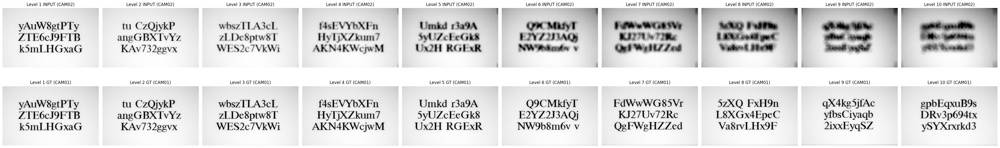

In [10]:
def pick_val(step, font=None):
    font = font or FIGURE_FONT
    c = df[(df.step == step) & (df.font == font) & (df.is_val)]
    if len(c) == 0:
        c = df[(df.step == step) & (df.is_val)]
    return int(c.index[0])

fig, axes = plt.subplots(2, 10, figsize=(40, 7))
for c, level in enumerate(LEVELS):
    i = pick_val(LEVELS[level])
    axes[0, c].imshow(Xb[i], cmap="gray", vmin=0, vmax=1); axes[0, c].set_title(f"Level {level} INPUT (CAM02)")
    axes[1, c].imshow(Yb[i], cmap="gray", vmin=0, vmax=1); axes[1, c].set_title(f"Level {level} GT (CAM01)")
    axes[0, c].axis("off"); axes[1, c].axis("off")
plt.tight_layout(); plt.show()

## 7. NAFNet model definition (unchanged)

In [11]:
class LayerNorm2d(nn.Module):
    # LayerNorm over channels, computed in float32 (safe with mixed precision)
    def __init__(self, channels, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(channels))
        self.bias = nn.Parameter(torch.zeros(channels))
        self.eps = eps

    def forward(self, x):
        dt = x.dtype
        x = x.float()
        mu = x.mean(1, keepdim=True)
        var = (x - mu).pow(2).mean(1, keepdim=True)
        y = (x - mu) / torch.sqrt(var + self.eps)
        y = self.weight.view(1, -1, 1, 1) * y + self.bias.view(1, -1, 1, 1)
        return y.to(dt)


class SimpleGate(nn.Module):
    def forward(self, x):
        a, b = x.chunk(2, dim=1)
        return a * b


class NAFBlock(nn.Module):
    def __init__(self, c, dw_expand=2, ffn_expand=2):
        super().__init__()
        dw = c * dw_expand
        self.conv1 = nn.Conv2d(c, dw, 1)
        self.conv2 = nn.Conv2d(dw, dw, 3, padding=1, groups=dw)
        self.conv3 = nn.Conv2d(dw // 2, c, 1)
        self.sca = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(dw // 2, dw // 2, 1))
        self.sg = SimpleGate()
        ffn = c * ffn_expand
        self.conv4 = nn.Conv2d(c, ffn, 1)
        self.conv5 = nn.Conv2d(ffn // 2, c, 1)
        self.norm1 = LayerNorm2d(c)
        self.norm2 = LayerNorm2d(c)
        self.beta = nn.Parameter(torch.zeros((1, c, 1, 1)))
        self.gamma = nn.Parameter(torch.zeros((1, c, 1, 1)))

    def forward(self, inp):
        x = self.norm1(inp)
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.sg(x)
        x = x * self.sca(x)
        x = self.conv3(x)
        y = inp + x * self.beta
        x = self.conv4(self.norm2(y))
        x = self.sg(x)
        x = self.conv5(x)
        return y + x * self.gamma


class NAFNet(nn.Module):
    def __init__(self, img_channel=3, width=32, middle_blk_num=1, enc_blk_nums=(), dec_blk_nums=()):
        super().__init__()
        self.intro = nn.Conv2d(img_channel, width, 3, padding=1)
        self.ending = nn.Conv2d(width, img_channel, 3, padding=1)
        self.encoders, self.decoders = nn.ModuleList(), nn.ModuleList()
        self.ups, self.downs = nn.ModuleList(), nn.ModuleList()
        chan = width
        for num in enc_blk_nums:
            self.encoders.append(nn.Sequential(*[NAFBlock(chan) for _ in range(num)]))
            self.downs.append(nn.Conv2d(chan, 2 * chan, 2, 2))
            chan *= 2
        self.middle_blks = nn.Sequential(*[NAFBlock(chan) for _ in range(middle_blk_num)])
        for num in dec_blk_nums:
            self.ups.append(nn.Sequential(nn.Conv2d(chan, chan * 2, 1, bias=False), nn.PixelShuffle(2)))
            chan //= 2
            self.decoders.append(nn.Sequential(*[NAFBlock(chan) for _ in range(num)]))
        self.padder_size = 2 ** len(self.encoders)

    def forward(self, inp):
        B, C, H, W = inp.shape
        ph = (self.padder_size - H % self.padder_size) % self.padder_size
        pw = (self.padder_size - W % self.padder_size) % self.padder_size
        inp = F.pad(inp, (0, pw, 0, ph))
        x = self.intro(inp)
        skips = []
        for enc, down in zip(self.encoders, self.downs):
            x = enc(x)
            skips.append(x)
            x = down(x)
        x = self.middle_blks(x)
        for dec, up, skip in zip(self.decoders, self.ups, skips[::-1]):
            x = up(x)
            x = x + skip
            x = dec(x)
        x = self.ending(x) + inp                      # global residual
        return x[:, :, :H, :W]


def build_nafnet():
    # NAFNet-GoPro-width32 configuration
    return NAFNet(img_channel=3, width=32, middle_blk_num=1,
                  enc_blk_nums=[1, 1, 1, 28], dec_blk_nums=[1, 1, 1, 1])

_tmp = build_nafnet()
print("Parameters: %.2f M  (official width-32 model: about 17.1 M)" % (sum(p.numel() for p in _tmp.parameters()) / 1e6))
del _tmp

Parameters: 17.11 M  (official width-32 model: about 17.1 M)


## 8. Official NAFNet-GoPro pretrained weights

In [12]:
PRETRAINED_URL  = "https://huggingface.co/mikestealth/nafnet-models/resolve/main/NAFNet-GoPro-width32.pth"
PRETRAINED_PATH = f"{ROOT}/NAFNet-GoPro-width32.pth"   # or upload the official file here yourself

if not (os.path.exists(PRETRAINED_PATH) and os.path.getsize(PRETRAINED_PATH) > 60e6):
    get_ipython().system(f'wget -c "{PRETRAINED_URL}" -O "{PRETRAINED_PATH}"')

def load_pretrained():
    try:
        ck = torch.load(PRETRAINED_PATH, map_location="cpu", weights_only=True)
        sd = ck["params"] if "params" in ck else ck
        net = build_nafnet()
        net.load_state_dict(sd, strict=True)
        print("Pretrained NAFNet-GoPro-width32 loaded")
        return net.to(device).eval()
    except Exception as e:
        print("!! Could not load pretrained weights:", repr(e)[:300])
        return None

pretrained_net = load_pretrained()
if pretrained_net is None and INIT_MODE == "pretrained":
    print("!! INIT_MODE is 'pretrained' but weights are missing -> training will start from scratch")
    INIT_MODE = "scratch"; RUN_NAME = f"scratch_{TAG}"

--2026-10-25 12:20:17--  https://huggingface.co/mikestealth/nafnet-models/resolve/main/NAFNet-GoPro-width32.pth
Resolving huggingface.co (huggingface.co)... 13.35.202.40, 13.35.202.97, 13.35.202.34, ...
Connecting to huggingface.co (huggingface.co)|13.35.202.40|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/674632501310ed05c6ca5ce7/dcad34039e167e38774bb91c91b6180f19cf4d1fa4ecd9d6a4cbe0ff8192747b?user_id=public&xip=F0qjP6r_-Yw&X-Xet-Cas-Uid=public&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27NAFNet-GoPro-width32.pth%3B+filename%3D%22NAFNet-GoPro-width32.pth%22%3B&Expires=1792934417&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjc0NjMyNTAxMzEwZWQwNWM2Y2E1Y2U3L2RjYWQzNDAzOWUxNjdlMzg3NzRiYjkxYzkxYjYxODBmMTljZjRkMWZhNGVjZDlkNmE0Y2JlMGZmODE5Mjc0N2JcXD91c2VyX2lkPXB1YmxpYyZ4aXA9RjBxalA2cl8tWXcmWC1YZXQtQ2FzLVVpZD1wdWJsaWMmcmVzcG9uc2UtY29udGVudC1kaXNwb3NpdGlvb

## 9. Data on GPU, loss, EMA, restore(), PSNR helpers (unchanged)

In [13]:
X = torch.from_numpy(Xb)[:, None].to(device)        # (N,1,H,W) blurred input  (CAM02)
Y = torch.from_numpy(Yb)[:, None].to(device)        # (N,1,H,W) sharp target   (CAM01)
train_idx = df.index[~df.is_val].tolist()
val_idx   = df.index[df.is_val].tolist()
print("train pairs:", len(train_idx), "| val pairs:", len(val_idx))

def random_batch(bs=BATCH, crop=CROP):
    ids = np.random.choice(train_idx, bs)
    xs, ys = [], []
    for i in ids:
        t, l = crop_origin(H, W, bboxes[i], crop)
        xs.append(X[i, :, t:t + crop, l:l + crop])
        ys.append(Y[i, :, t:t + crop, l:l + crop])
    return torch.stack(xs).repeat(1, 3, 1, 1), torch.stack(ys).repeat(1, 3, 1, 1)

def fft_l1(a, b):
    return (torch.fft.rfft2(a, norm="ortho") - torch.fft.rfft2(b, norm="ortho")).abs().mean()

def loss_fn(pred, target):
    return F.l1_loss(pred, target) + 0.1 * fft_l1(pred, target)

class EMA:
    def __init__(self, model, decay=0.999):
        self.model = copy.deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)
        self.decay, self.n = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))
        for pe, pm in zip(self.model.parameters(), model.parameters()):
            pe.mul_(d).add_(pm.detach(), alpha=1 - d)

@torch.no_grad()
def restore(model, x1):
    # x1: (1,1,H,W) in [0,1]  ->  (1,1,H,W) in [0,1]   (full image, float32)
    model.eval()
    _, _, h, w = x1.shape
    x = x1.repeat(1, 3, 1, 1)
    ph, pw = (-h) % 16, (-w) % 16
    if ph or pw:
        x = F.pad(x, (0, pw, 0, ph), mode="reflect")
    y = model(x)[:, :, :h, :w]
    return y.mean(1, keepdim=True).clamp(0, 1)

def psnr_t(a, b):
    return float(-10 * torch.log10(F.mse_loss(a, b) + 1e-12))

@torch.no_grad()
def evaluate(model, idxs):
    return float(np.mean([psnr_t(restore(model, X[i:i + 1]), Y[i:i + 1]) for i in idxs]))

in_psnr = float(np.mean([psnr_t(X[i:i + 1], Y[i:i + 1]) for i in val_idx]))
print("Validation PSNR  | blurred input : %.2f dB" % in_psnr)
pre_psnr = None
if pretrained_net is not None:
    pre_psnr = evaluate(pretrained_net, val_idx)
    print("Validation PSNR  | pretrained (no fine-tuning): %.2f dB" % pre_psnr)

train pairs: 340 | val pairs: 60
Validation PSNR  | blurred input : 16.04 dB
Validation PSNR  | pretrained (no fine-tuning): 12.15 dB


In [17]:
import gc
for _n in ["model", "opt", "ema", "scaler", "pred", "loss", "xb", "yb"]:
    if _n in globals():
        del globals()[_n]
gc.collect(); torch.cuda.empty_cache()
print("GPU memory used (GB):", round(torch.cuda.memory_allocated() / 1e9, 2))

GPU memory used (GB): 8.12


## 10. TRAIN ONCE on all 10 levels

In [18]:
TOTAL_ITERS = 5000   # override: shorter training
USE_AMP = False      # override: fp16 gave NaN loss
BATCH_NOW = 4        # override: batch 8 runs out of GPU memory in fp32

model = build_nafnet().to(device)
if INIT_MODE == "pretrained":
    model.load_state_dict(pretrained_net.state_dict())
    base_lr = LR_FINETUNE
else:
    base_lr = LR_SCRATCH
print("Init:", INIT_MODE, "| base lr:", base_lr, "| iters:", TOTAL_ITERS, "| batch:", BATCH_NOW, "| AMP:", USE_AMP)

opt = torch.optim.AdamW(model.parameters(), lr=base_lr, betas=(0.9, 0.9), weight_decay=0)
amp_on = bool(USE_AMP and device.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=amp_on)
ema = EMA(model, decay=0.999)
WARMUP, MIN_LR = 200, 1e-6

def lr_at(it):
    if it < WARMUP:
        return base_lr * (it + 1) / WARMUP
    p = (it - WARMUP) / max(1, TOTAL_ITERS - WARMUP)
    return MIN_LR + 0.5 * (base_lr - MIN_LR) * (1 + math.cos(math.pi * p))

loss_hist, val_hist = [], []
best_psnr, best_state = -1.0, None
run_loss, t0, skipped = 0.0, time.time(), 0

for it in range(1, TOTAL_ITERS + 1):
    model.train()
    for g in opt.param_groups:
        g["lr"] = lr_at(it - 1)

    xb, yb = random_batch(bs=BATCH_NOW)
    with torch.autocast("cuda", dtype=torch.float16, enabled=amp_on):
        pred = model(xb)
    loss = loss_fn(pred.float(), yb)
    if not torch.isfinite(loss):
        skipped += 1
        opt.zero_grad(set_to_none=True)
        if skipped in (1, 10, 100):
            print(f"⚠️ non-finite loss at iter {it} (skipped {skipped} so far)", flush=True)
        continue

    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt)
    scaler.update()
    ema.update(model)

    run_loss += loss.item()
    if it % 50 == 0:
        loss_hist.append((it, run_loss / 50)); run_loss = 0.0

    if it == 50 or (it % 100 == 0 and it < 500):
        print(f"iter {it} | loss {loss_hist[-1][1]:.4f} | {(time.time()-t0)/60:.1f} min", flush=True)

    if it % 500 == 0 or it == TOTAL_ITERS:
        v = evaluate(ema.model, val_idx)
        val_hist.append((it, v))
        if v > best_psnr:
            best_psnr = v
            best_state = {k: t.detach().cpu().clone() for k, t in ema.model.state_dict().items()}
            torch.save(best_state, f"{ROOT}/ckpt_best_{TAG}.pth")
        el = (time.time() - t0) / 60
        print(f"✅ {it}/{TOTAL_ITERS} iterations done ({100*it/TOTAL_ITERS:.0f}%) | "
              f"loss {loss_hist[-1][1]:.4f} | val PSNR {v:.2f} dB (best {best_psnr:.2f}) | "
              f"{el:.1f} min elapsed | ~{el/it*(TOTAL_ITERS-it):.1f} min left", flush=True)

print("Training finished. Best validation PSNR: %.2f dB | skipped iters: %d" % (best_psnr, skipped))

Init: pretrained | base lr: 0.0002 | iters: 5000 | batch: 4 | AMP: False
iter 50 | loss 2.9949 | 0.4 min
iter 100 | loss 0.7563 | 0.7 min
iter 200 | loss 0.3816 | 1.4 min
iter 300 | loss 0.0855 | 2.0 min
iter 400 | loss 0.0823 | 2.7 min
✅ 500/5000 iterations done (10%) | loss 0.0810 | val PSNR 17.68 dB (best 17.68) | 3.5 min elapsed | ~31.1 min left
✅ 1000/5000 iterations done (20%) | loss 0.0590 | val PSNR 18.65 dB (best 18.65) | 6.9 min elapsed | ~27.5 min left
✅ 1500/5000 iterations done (30%) | loss 0.0590 | val PSNR 19.12 dB (best 19.12) | 10.3 min elapsed | ~24.0 min left
✅ 2000/5000 iterations done (40%) | loss 0.0484 | val PSNR 19.18 dB (best 19.18) | 13.7 min elapsed | ~20.6 min left
✅ 2500/5000 iterations done (50%) | loss 0.0506 | val PSNR 19.28 dB (best 19.28) | 17.1 min elapsed | ~17.1 min left
✅ 3000/5000 iterations done (60%) | loss 0.0476 | val PSNR 19.23 dB (best 19.28) | 20.6 min elapsed | ~13.7 min left
✅ 3500/5000 iterations done (70%) | loss 0.0417 | val PSNR 19.14

## 11. Save the model + training curves

Saved model: /kaggle/working/nafnet_steps0to9.pth


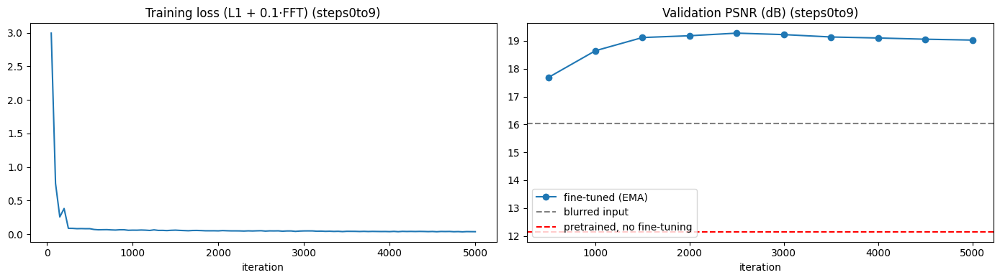

In [19]:
MODEL_PATH = f"{ROOT}/nafnet_{TAG}.pth"            # -> /kaggle/working/nafnet_steps0to9.pth
torch.save(best_state, MODEL_PATH)
print("Saved model:", MODEL_PATH)

finetuned_net = build_nafnet().to(device)
finetuned_net.load_state_dict(best_state)
finetuned_net.eval()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
its, ls = zip(*loss_hist)
ax[0].plot(its, ls); ax[0].set_title(f"Training loss (L1 + 0.1·FFT) ({TAG})"); ax[0].set_xlabel("iteration")
its, vs = zip(*val_hist)
ax[1].plot(its, vs, marker="o", label="fine-tuned (EMA)")
ax[1].axhline(in_psnr, color="gray", ls="--", label="blurred input")
if pre_psnr is not None:
    ax[1].axhline(pre_psnr, color="red", ls="--", label="pretrained, no fine-tuning")
ax[1].set_title(f"Validation PSNR (dB) ({TAG})"); ax[1].set_xlabel("iteration"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{ROOT}/results/curves_{TAG}.png", dpi=120, bbox_inches="tight"); plt.show()

## 12. Before/after pictures for every level

Processing: level 1
Running pretrained...
Running fine-tuned...


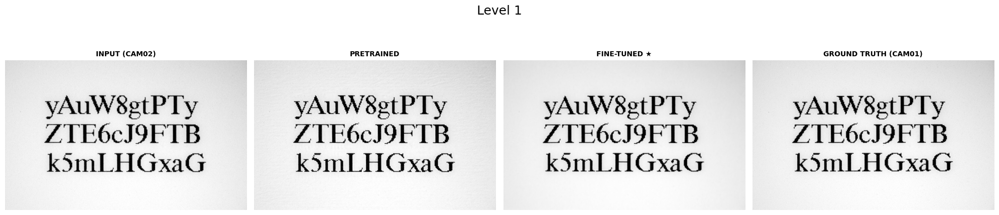

Processing: level 2
Running pretrained...
Running fine-tuned...


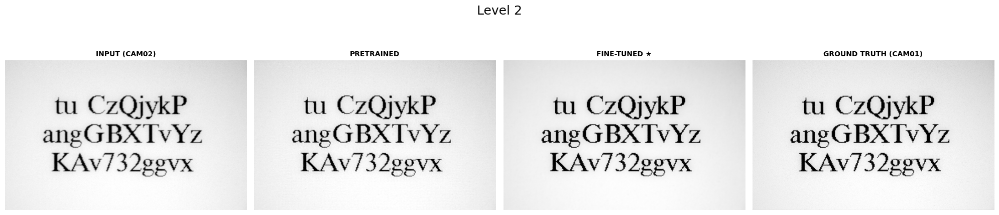

Processing: level 3
Running pretrained...
Running fine-tuned...


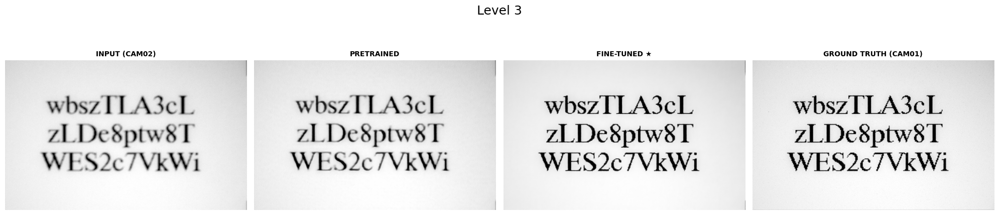

Processing: level 4
Running pretrained...
Running fine-tuned...


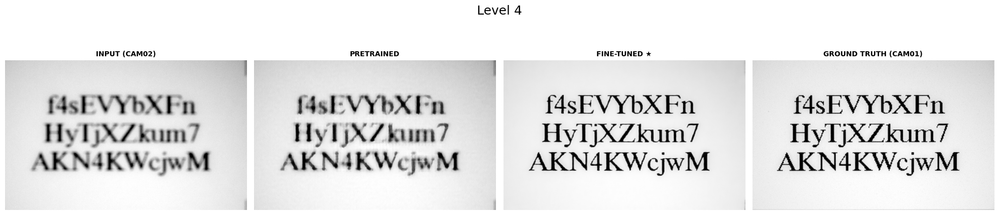

Processing: level 5
Running pretrained...
Running fine-tuned...


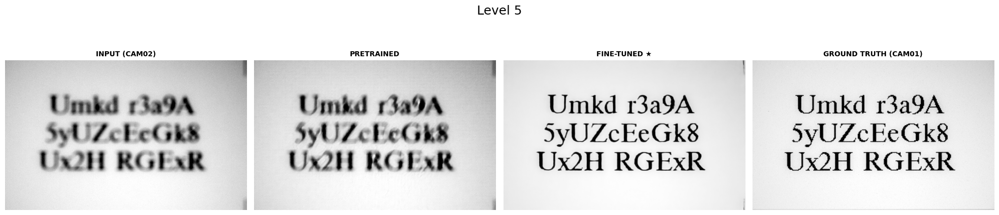

Processing: level 6
Running pretrained...
Running fine-tuned...


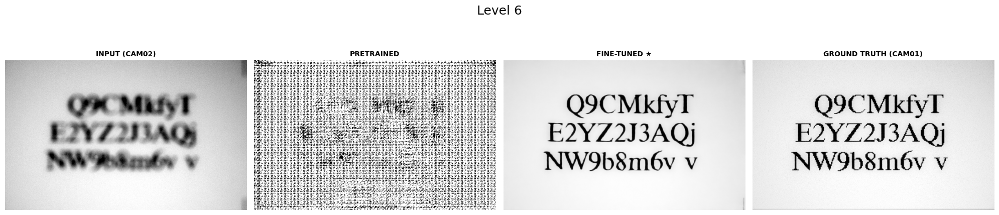

Processing: level 7
Running pretrained...
Running fine-tuned...


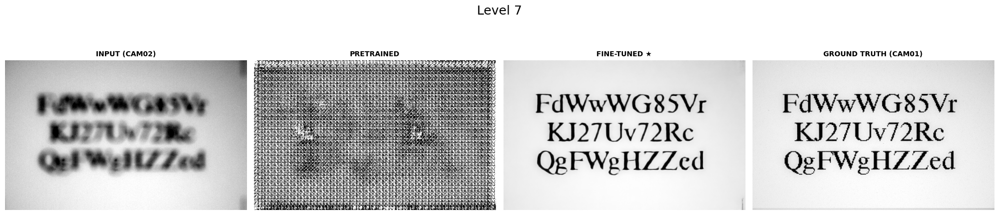

Processing: level 8
Running pretrained...
Running fine-tuned...


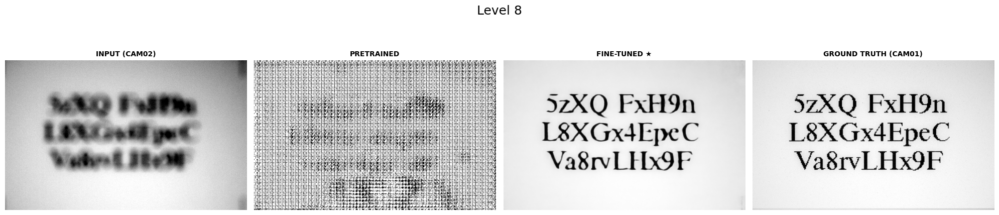

Processing: level 9
Running pretrained...
Running fine-tuned...


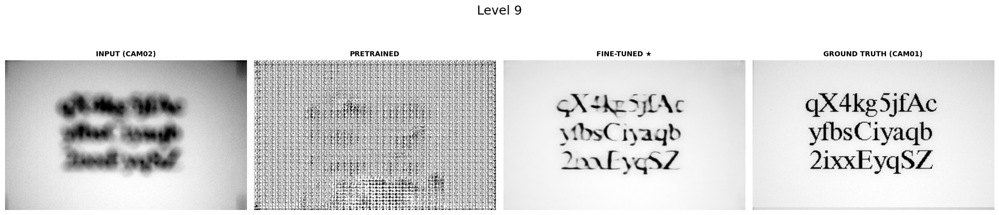

Processing: level 10
Running pretrained...
Running fine-tuned...


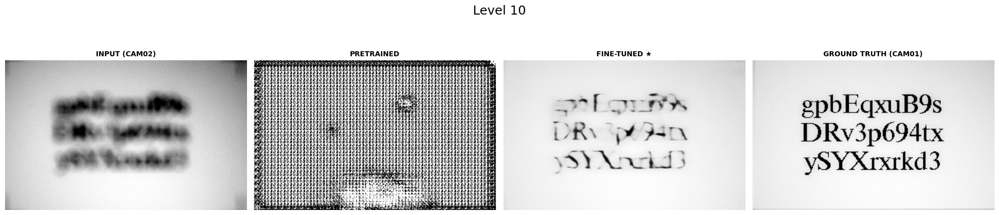

In [20]:
def show_level(level, font=FIGURE_FONT):
    step = LEVELS[level]
    i = pick_val(step, font)   # held-out image

    print(f"Processing: level {level}")
    x, gt = X[i:i + 1], Y[i:i + 1]

    print("Running pretrained...")
    pre = restore(pretrained_net, x) if pretrained_net is not None else None
    print("Running fine-tuned...")
    fin = restore(finetuned_net, x)

    def img(t):
        return t.squeeze().detach().cpu().numpy()

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    fig.suptitle(f"Level {level}", fontsize=18)
    panels = [("INPUT (CAM02)", img(x)), ("PRETRAINED", None if pre is None else img(pre)),
              ("FINE-TUNED ★", img(fin)), ("GROUND TRUTH (CAM01)", img(gt))]
    for ax, (title, im) in zip(axes, panels):
        if im is None:
            ax.text(0.5, 0.5, "not available", ha="center", va="center")
        else:
            ax.imshow(im, cmap="gray", vmin=0, vmax=1)
        ax.set_title(title, fontsize=10, fontweight="bold")
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"{ROOT}/results/level_{level}_{RUN_NAME}.png", dpi=120, bbox_inches="tight")
    plt.show()

for level in LEVELS:
    show_level(level)

## 13. PSNR / SSIM per level

In [21]:
def ssim_np(a, b):
    return structural_similarity(a, b, data_range=1.0)

rows = []
for level, step in LEVELS.items():
    idxs = df.index[(df.step == step) & (df.is_val)].tolist()
    r = dict(Level=level, n_images=len(idxs))
    accs = {"in_p": [], "in_s": [], "pre_p": [], "pre_s": [], "fin_p": [], "fin_s": []}
    for i in idxs:
        gt = Y[i:i + 1]
        gt_np = gt.squeeze().cpu().numpy()
        outs = {"in": X[i:i + 1], "fin": restore(finetuned_net, X[i:i + 1])}
        if pretrained_net is not None:
            outs["pre"] = restore(pretrained_net, X[i:i + 1])
        for k, o in outs.items():
            accs[k + "_p"].append(psnr_t(o, gt))
            accs[k + "_s"].append(ssim_np(o.squeeze().cpu().numpy(), gt_np))
    r["Input PSNR"], r["Input SSIM"] = np.mean(accs["in_p"]), np.mean(accs["in_s"])
    if pretrained_net is not None:
        r["Pretrained PSNR"], r["Pretrained SSIM"] = np.mean(accs["pre_p"]), np.mean(accs["pre_s"])
    r["Fine-tuned PSNR"], r["Fine-tuned SSIM"] = np.mean(accs["fin_p"]), np.mean(accs["fin_s"])
    rows.append(r)

res = pd.DataFrame(rows).set_index("Level")
res.loc["mean"] = res.mean()
display(res.round(3))
res.to_csv(f"{ROOT}/results/metrics_{TAG}.csv")

,n_images,Input PSNR,Input SSIM,Pretrained PSNR,Pretrained SSIM,Fine-tuned PSNR,Fine-tuned SSIM
Level,,,,,,,
1,6.0,20.825,0.755,20.436,0.742,23.494,0.848
2,6.0,24.695,0.824,24.925,0.824,29.832,0.876
3,6.0,20.237,0.759,20.027,0.771,24.607,0.853
4,6.0,17.525,0.674,17.433,0.705,20.902,0.821
5,6.0,15.190,0.591,13.900,0.520,18.531,0.791
6,6.0,13.718,0.535,7.524,0.066,17.328,0.771
7,6.0,12.607,0.488,5.026,0.005,15.909,0.742
8,6.0,12.175,0.474,4.067,0.004,14.768,0.719
9,6.0,11.824,0.473,4.186,0.004,13.858,0.687


In [22]:
L4 = [1, 2, 3, 4]
d4 = df[df.step.isin([LEVELS[l] for l in L4])]
print("Levels 1-4 | total pairs:", len(d4), "| train:", int((~d4.is_val).sum()), "| test:", int(d4.is_val.sum()))
display(pd.crosstab([d4.step, d4.is_val], d4.font))
print("Split: last", HOLDOUT_PER_GROUP, "samples (by sample number) of each (level, font) held out")

t4 = res.loc[L4, ["Input PSNR", "Input SSIM", "Fine-tuned PSNR", "Fine-tuned SSIM"]].copy()
t4["fine-tuned > input (PSNR)"] = t4["Fine-tuned PSNR"] > t4["Input PSNR"]
display(t4.round(3))

Levels 1-4 | total pairs: 160 | train: 136 | test: 24


font         timesR  verdanaRef
step is_val                    
0    False       17          17
     True         3           3
1    False       17          17
     True         3           3
2    False       17          17
     True         3           3
3    False       17          17
     True         3           3

Split: last 3 samples (by sample number) of each (level, font) held out


,Input PSNR,Input SSIM,Fine-tuned PSNR,Fine-tuned SSIM,fine-tuned > input (PSNR)
Level,,,,,
1,20.825,0.755,23.494,0.848,True
2,24.695,0.824,29.832,0.876,True
3,20.237,0.759,24.607,0.853,True
4,17.525,0.674,20.902,0.821,True


## 14. OCR for every level + save model, tables and OCR pack into one zip

In [23]:
# ===== OCR (EasyOCR): blurred input vs NAFNet output, every level, held-out images =====
get_ipython().system("pip -q install easyocr rapidfuzz")
import easyocr, cv2, shutil
from rapidfuzz.distance import Levenshtein

OCR_UPSCALE = 4                                   # outputs are 1/4 scale -> upscale before OCR
SAVE_DIR = f"{ROOT}/nafnet_saved"
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(f"{ROOT}/results/nafnet_out", exist_ok=True)
reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available())

def norm_txt(s): return " ".join(s.split())

def read_gt(i):                                   # ground-truth text sits next to the blurred tif
    stem = os.path.splitext(df["name"][i])[0]
    with open(os.path.join(df["blur_dir"][i], stem + ".txt"), encoding="utf-8", errors="ignore") as f:
        return norm_txt(f.read())

def ocr_text(img01):
    im = (np.clip(img01, 0, 1) * 255).astype(np.uint8)
    if OCR_UPSCALE != 1:
        im = cv2.resize(im, None, fx=OCR_UPSCALE, fy=OCR_UPSCALE, interpolation=cv2.INTER_CUBIC)
    return norm_txt(" ".join(reader.readtext(im, detail=0, paragraph=True)))

def acc_score(ref, hyp, tokens=False):            # 1 - edit distance / reference length (clipped at 0)
    r, h = (ref.split(), hyp.split()) if tokens else (ref, hyp)
    return max(0.0, 1 - Levenshtein.distance(r, h) / max(1, len(r)))

gts = {i: read_gt(i) for i in df.index[df.is_val]}
rows = []
for level, step in LEVELS.items():
    for i in tqdm(df.index[(df.step == step) & df.is_val], desc=f"OCR level {level}"):
        x = X[i:i + 1]
        out = restore(finetuned_net, x)
        Image.fromarray((out.squeeze().cpu().numpy() * 255).astype(np.uint8)).save(
            f"{ROOT}/results/nafnet_out/L{level}_{os.path.splitext(df['name'][i])[0]}.png")
        for k, t in {"blurred": x, "nafnet": out}.items():
            hyp = ocr_text(t.squeeze().cpu().numpy())
            rows.append(dict(level=level, model=k, name=df["name"][i],
                             char_acc=acc_score(gts[i], hyp), tok_acc=acc_score(gts[i], hyp, True)))

ocr = pd.DataFrame(rows)
final = ocr.groupby(["level", "model"])[["char_acc", "tok_acc"]].mean().mul(100).round(1).unstack("model")
final["n"] = ocr[ocr.model == "nafnet"].groupby("level").size()
display(final)

# ===== save everything worth keeping into ONE zip =====
ocr.to_csv(f"{SAVE_DIR}/ocr_per_image_{TAG}.csv", index=False)
final.to_csv(f"{SAVE_DIR}/ocr_all_levels_{TAG}.csv")                     # <- your NAFNet column
shutil.copy(MODEL_PATH, f"{SAVE_DIR}/nafnet_{TAG}.pth")                   # <- trained model
shutil.copy(f"{ROOT}/results/metrics_{TAG}.csv", SAVE_DIR)
shutil.copy(f"{ROOT}/results/curves_{TAG}.png", SAVE_DIR)
vi = df.index[df.is_val].tolist()                                         # small pack: OCR without the 5.6 GB data
np.savez_compressed(f"{SAVE_DIR}/ocr_pack_{TAG}.npz", X=Xb[vi], names=df["name"].values[vi],
                    step=df["step"].values[vi], gt=np.array([gts[i] for i in vi]))
for f in glob.glob(f"{ROOT}/results/level_*_{RUN_NAME}.png"):                # before/after comparison pictures
    shutil.copy(f, SAVE_DIR)
shutil.copytree(f"{ROOT}/results/nafnet_out", f"{SAVE_DIR}/nafnet_out", dirs_exist_ok=True)   # restored images used for OCR
shutil.make_archive(f"{ROOT}/nafnet_saved", "zip", SAVE_DIR)
print("DONE. Download:", f"{ROOT}/nafnet_saved.zip")
print(sorted(os.listdir(SAVE_DIR)))

OCR level 1:   0%|          | 0/6 [00:00<?, ?it/s]

OCR level 2:   0%|          | 0/6 [00:00<?, ?it/s]

OCR level 3:   0%|          | 0/6 [00:00<?, ?it/s]

OCR level 4:   0%|          | 0/6 [00:00<?, ?it/s]

OCR level 5:   0%|          | 0/6 [00:00<?, ?it/s]

...

OCR level 8:   0%|          | 0/6 [00:00<?, ?it/s]

OCR level 9:   0%|          | 0/6 [00:00<?, ?it/s]

OCR level 10:   0%|          | 0/6 [00:00<?, ?it/s]

char_acc        tok_acc         n
model  blurred nafnet blurred nafnet   
level                                  
1         87.9   93.2    30.3   40.6  6
2         95.3   92.2    70.8   50.0  6
3         88.0   92.2    29.2   34.7  6
4         77.5   93.7    15.3   54.2  6
5         39.1   92.2     0.0   54.4  6
6          7.8   94.1     0.0   59.2  6
7          0.0   92.2     0.0   52.8  6
8          0.0   89.0     0.0   37.5  6
9          0.0   71.5     0.0   23.6  6
10         0.0   29.3     0.0    0.0  6

DONE. Download: /kaggle/working/nafnet_saved.zip
['curves_steps0to9.png', 'level_10_pretrained_steps0to9.png', 'level_1_pretrained_steps0to9.png', 'level_2_pretrained_steps0to9.png', 'level_3_pretrained_steps0to9.png', 'level_4_pretrained_steps0to9.png', 'level_5_pretrained_steps0to9.png', 'level_6_pretrained_steps0to9.png', 'level_7_pretrained_steps0to9.png', 'level_8_pretrained_steps0to9.png', 'level_9_pretrained_steps0to9.png', 'metrics_steps0to9.csv', 'nafnet_out', 'nafnet_steps0to9.pth', 'ocr_all_levels_steps0to9.csv', 'ocr_pack_steps0to9.npz', 'ocr_per_image_steps0to9.csv']


In [24]:
# ===== Tables 8 & 9: NAFNet rows, Levels 1-4 =====
L4 = [1, 2, 3, 4]

# ---- Table 8: PSNR / SSIM (from the `res` table of section 13) ----
print("TABLE 8  (PSNR dB / SSIM)      " + "  ".join(f"Level {l}      " for l in L4))
for name, p, s in [("Blurred input", "Input PSNR", "Input SSIM"),
                   ("NAFNet (fine-tuned)", "Fine-tuned PSNR", "Fine-tuned SSIM")]:
    print(f"{name:30s}" + "  ".join(f"{res.loc[l, p]:.2f} / {res.loc[l, s]:.3f}" for l in L4))

# ---- Table 9: CER per level + mean WER (corpus-level, not clipped) ----
def edits(ref, hyp, tokens=False):
    r, h = (ref.split(), hyp.split()) if tokens else (ref, hyp)
    return Levenshtein.distance(r, h), len(r)

models = ["sharp", "blurred", "nafnet"]
cer = {m: {l: [0, 0] for l in L4} for m in models}   # [edits, ref length]
wer = {m: [0, 0] for m in models}

for l in L4:
    for i in tqdm(df.index[(df.step == LEVELS[l]) & df.is_val], desc=f"Level {l}"):
        ref = gts[i]
        imgs = {"sharp": Y[i:i + 1], "blurred": X[i:i + 1], "nafnet": restore(finetuned_net, X[i:i + 1])}
        for m, t in imgs.items():
            hyp = ocr_text(t.squeeze().cpu().numpy())
            e, n = edits(ref, hyp);        cer[m][l][0] += e; cer[m][l][1] += n
            e, n = edits(ref, hyp, True);  wer[m][0] += e;    wer[m][1] += n

names = {"sharp": "Ground truth (sharp)", "blurred": "Blurred input", "nafnet": "NAFNet (fine-tuned)"}
rows9 = []
print("\nTABLE 9  (CER % per level, mean WER %)")
print(f"{'Method':24s}" + "".join(f"CER L{l:<5d}" for l in L4) + "WER (mean)")
for m in models:
    c = [100 * cer[m][l][0] / max(1, cer[m][l][1]) for l in L4]
    w = 100 * wer[m][0] / max(1, wer[m][1])
    rows9.append([names[m]] + c + [w])
    print(f"{names[m]:24s}" + "".join(f"{v:<9.2f}" for v in c) + f"{w:.2f}")

pd.DataFrame(rows9, columns=["Method", "CER L1", "CER L2", "CER L3", "CER L4", "WER mean"]) \
  .to_csv(f"{ROOT}/results/table9_nafnet_{TAG}.csv", index=False)

TABLE 8  (PSNR dB / SSIM)      Level 1        Level 2        Level 3        Level 4      
Blurred input                 20.82 / 0.755  24.70 / 0.824  20.24 / 0.759  17.52 / 0.674
NAFNet (fine-tuned)           23.49 / 0.848  29.83 / 0.876  24.61 / 0.853  20.90 / 0.821


Level 1:   0%|          | 0/6 [00:00<?, ?it/s]

Level 2:   0%|          | 0/6 [00:00<?, ?it/s]

Level 3:   0%|          | 0/6 [00:00<?, ?it/s]

Level 4:   0%|          | 0/6 [00:00<?, ?it/s]


TABLE 9  (CER % per level, mean WER %)
Method                  CER L1    CER L2    CER L3    CER L4    WER (mean)
Ground truth (sharp)    12.63    9.38     14.58    7.85     74.07
Blurred input           12.11    4.69     11.98    22.51    71.60
NAFNet (fine-tuned)     6.84     7.81     7.81     6.28     53.09


In [25]:
from IPython.display import FileLink, display
os.chdir("/kaggle/working")
for f in ["nafnet_saved.zip",
          "results/metrics_steps0to9.csv",
          "results/table9_nafnet_steps0to9.csv"]:
    if os.path.exists(f):
        display(FileLink(f))
    else:
        print("not found yet:", f)

/kaggle/working/nafnet_saved.zip

/kaggle/working/results/metrics_steps0to9.csv

/kaggle/working/results/table9_nafnet_steps0to9.csv

In [26]:
import glob, time

print("Saved model files:")
for f in sorted(glob.glob("/kaggle/working/**/*.pth", recursive=True)):
    print(f"  {f} | {os.path.getsize(f)/1e6:.1f} MB | {time.ctime(os.path.getmtime(f))}")

# check that the final model loads and is valid
p = f"{ROOT}/nafnet_{TAG}.pth"
if os.path.exists(p):
    net = build_nafnet()
    net.load_state_dict(torch.load(p, map_location="cpu", weights_only=True), strict=True)
    print("\n✅ nafnet_%s.pth loads fine (strict=True)" % TAG)
else:
    print("\n❌ nafnet_%s.pth not found - run section 11 first" % TAG)

Saved model files:
  /kaggle/working/NAFNet-GoPro-width32.pth | 68.7 MB | Sun Oct 25 12:20:19 2026
  /kaggle/working/ckpt_best_steps0to9.pth | 68.7 MB | Sun Oct 25 13:05:13 2026
  /kaggle/working/nafnet_saved/nafnet_steps0to9.pth | 68.7 MB | Sun Oct 25 13:24:44 2026
  /kaggle/working/nafnet_steps0to9.pth | 68.7 MB | Sun Oct 25 13:22:18 2026

✅ nafnet_steps0to9.pth loads fine (strict=True)
